<a href="https://colab.research.google.com/github/YASHAS-KING/BIS_LAB/blob/main/Genetic_Algorithm_for_Optimization_Problems_bis_p1.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Starting Genetic Algorithm Optimization across 20 generations...

Generation   1 | Best Fitness: 3.64784 | Best x: 1.65235
Generation  20 | Best Fitness: 3.85027 | Best x: 1.85055

OPTIMIZATION COMPLETE
Optimal x found:       1.850549
Maximum f(x) achieved: 3.850274


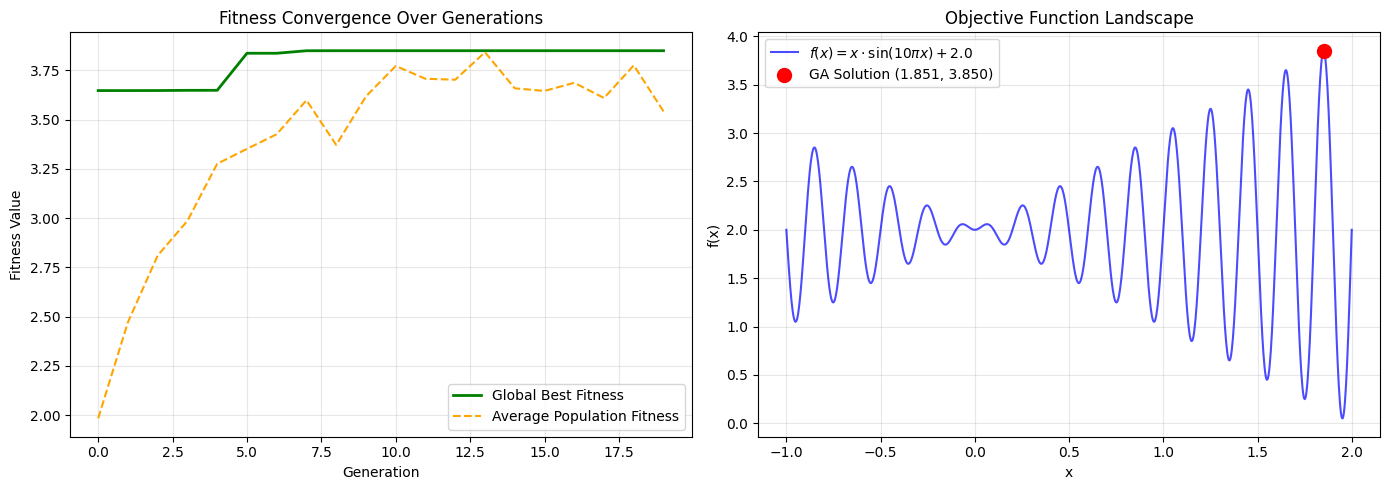

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

# ==========================================
# 1. PROBLEM & FITNESS FUNCTION
# ==========================================
BOUNDS = [-1.0, 2.0]  # Search space domain x in [-1, 2]
CHROMOSOME_LENGTH = 20 # Bit precision

def objective_function(x):
    """Target mathematical function: f(x) = x * sin(10 * pi * x) + 2.0"""
    return x * np.sin(10 * np.pi * x) + 2.0

def decode_chromosome(chromosome, bounds, length):
    """Converts a binary bitstring array into a real continuous scalar x."""
    # Convert binary vector to decimal integer
    decimal_val = int("".join(map(str, chromosome)), 2)
    # Map integer scale to defined range [bounds[0], bounds[1]]
    max_decimal = (2**length) - 1
    real_x = bounds[0] + (decimal_val / max_decimal) * (bounds[1] - bounds[0])
    return real_x

# ==========================================
# 2. ALGORITHM OPERATORS
# ==========================================
def initialize_population(pop_size, chrom_length):
    """Generates initial uniform random bit matrix."""
    return np.random.randint(0, 2, size=(pop_size, chrom_length))

def calculate_fitness(population, bounds, chrom_length):
    """Evaluates fitness scores for every individual in the population."""
    phenotypes = np.array([decode_chromosome(ind, bounds, chrom_length) for ind in population])
    fitness_scores = objective_function(phenotypes)
    return fitness_scores, phenotypes

def tournament_selection(population, fitness_scores, k=3):
    """Selects one parent using tournament selection."""
    selected_indices = np.random.choice(len(population), size=k, replace=False)
    best_index = selected_indices[np.argmax(fitness_scores[selected_indices])]
    return population[best_index].copy()

def single_point_crossover(parent1, parent2, crossover_rate):
    """Combines two parents to create two offspring using single-point crossover."""
    if np.random.rand() < crossover_rate:
        crossover_point = np.random.randint(1, len(parent1))
        child1 = np.concatenate((parent1[:crossover_point], parent2[crossover_point:]))
        child2 = np.concatenate((parent2[:crossover_point], parent1[crossover_point:]))
        return child1, child2
    return parent1.copy(), parent2.copy()

def bit_flip_mutation(individual, mutation_rate):
    """Mutates bits within an individual with probability mutation_rate."""
    for i in range(len(individual)):
        if np.random.rand() < mutation_rate:
            individual[i] = 1 - individual[i]  # Flip bit
    return individual

# ==========================================
# 3. MAIN GENETIC ALGORITHM ENGINE
# ==========================================
def run_genetic_algorithm(
    pop_size=50,
    chrom_length=20,
    generations=20,
    crossover_rate=0.8,
    mutation_rate=0.01
):
    # Step 3: Initialize Population
    population = initialize_population(pop_size, chrom_length)

    best_fitness_history = []
    avg_fitness_history = []

    global_best_individual = None
    global_best_fitness = -np.inf
    global_best_x = None

    print(f"Starting Genetic Algorithm Optimization across {generations} generations...\n")

    # Step 8: Evolutionary Loop
    for gen in range(generations):
        # Step 4: Evaluate Fitness
        fitness_scores, phenotypes = calculate_fitness(population, BOUNDS, chrom_length)

        # Track historical bests
        current_best_idx = np.argmax(fitness_scores)
        current_best_fitness = fitness_scores[current_best_idx]
        current_best_x = phenotypes[current_best_idx]

        if current_best_fitness > global_best_fitness:
            global_best_fitness = current_best_fitness
            global_best_individual = population[current_best_idx].copy()
            global_best_x = current_best_x

        best_fitness_history.append(global_best_fitness)
        avg_fitness_history.append(np.mean(fitness_scores))

        # Generate next generation
        new_population = []

        # Elitism: retain current best solution directly
        new_population.append(population[current_best_idx].copy())

        while len(new_population) < pop_size:
            # Step 5: Selection
            parent1 = tournament_selection(population, fitness_scores)
            parent2 = tournament_selection(population, fitness_scores)

            # Step 6: Crossover
            child1, child2 = single_point_crossover(parent1, parent2, crossover_rate)

            # Step 7: Mutation
            child1 = bit_flip_mutation(child1, mutation_rate)
            child2 = bit_flip_mutation(child2, mutation_rate)

            new_population.extend([child1, child2])

        # Truncate population to exact pop_size
        population = np.array(new_population[:pop_size])

        if (gen + 1) % 20 == 0 or gen == 0:
            print(f"Generation {gen+1:3d} | Best Fitness: {global_best_fitness:.5f} | Best x: {global_best_x:.5f}")

    # Step 9: Output Results
    print("\n" + "="*45)
    print("OPTIMIZATION COMPLETE")
    print("="*45)
    print(f"Optimal x found:       {global_best_x:.6f}")
    print(f"Maximum f(x) achieved: {global_best_fitness:.6f}")

    return best_fitness_history, avg_fitness_history, global_best_x, global_best_fitness

# ==========================================
# 4. EXECUTION & VISUALIZATION
# ==========================================
# Run Algorithm
best_history, avg_history, opt_x, opt_y = run_genetic_algorithm(
    pop_size=60,
    chrom_length=20,
    generations=20,
    crossover_rate=0.85,
    mutation_rate=0.015
)

# Plotting Visualizations
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Plot 1: Optimization Convergence Curve
axes[0].plot(best_history, label='Global Best Fitness', color='green', linewidth=2)
axes[0].plot(avg_history, label='Average Population Fitness', color='orange', linestyle='--')
axes[0].set_title('Fitness Convergence Over Generations')
axes[0].set_xlabel('Generation')
axes[0].set_ylabel('Fitness Value')
axes[0].grid(True, alpha=0.3)
axes[0].legend()

# Plot 2: Function Landscape and Found Optimal Point
x_vals = np.linspace(BOUNDS[0], BOUNDS[1], 1000)
y_vals = objective_function(x_vals)

axes[1].plot(x_vals, y_vals, label=r'$f(x) = x \cdot \sin(10\pi x) + 2.0$', color='blue', alpha=0.7)
axes[1].scatter([opt_x], [opt_y], color='red', s=100, zorder=5, label=f'GA Solution ({opt_x:.3f}, {opt_y:.3f})')
axes[1].set_title('Objective Function Landscape')
axes[1].set_xlabel('x')
axes[1].set_ylabel('f(x)')
axes[1].grid(True, alpha=0.3)
axes[1].legend()

plt.tight_layout()
plt.show()